# Wordle Tweet Analysis

Every day in early 2022, thousands of people posted their Wordle result to Twitter: the puzzle number, how many guesses it took, and a grid of coloured squares. This notebook turns 234,186 of those tweets into structured data and looks at how people actually play.

**Questions**
1. How many guesses does it usually take?
2. Which puzzles were hardest?
3. How much does the first guess matter?

The squares mean: 🟩 right letter, right spot · 🟨 right letter, wrong spot · ⬛ letter not in the word.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("ggplot")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

## 1. Load the data

In [2]:
tweets = pd.read_csv("tweets.csv.zip")
print(tweets.shape)
tweets.head()

(234186, 5)


,wordle_id,tweet_id,tweet_date,tweet_username,tweet_text
0,210,1482553374591660037,2022-01-16 03:20:43+00:00,bpszebes,Wordle 210 4/6\n\n⬛⬛🟨🟨⬛\n🟩⬛⬛⬛⬛\n🟩🟩🟨⬛⬛\n🟩🟩🟩🟩🟩
1,210,1482553387937898499,2022-01-16 03:20:46+00:00,cruisecoup,Wordle 210 4/6\n\n⬜⬜⬜⬜⬜\n🟩🟩🟨🟨⬜\n🟩🟩⬜🟩🟨\n🟩🟩🟩🟩🟩
2,210,1482553422276698113,2022-01-16 03:20:55+00:00,DestroVega,Wordle 210 4/6\n\n⬜⬜⬜🟨⬜\n⬜🟩⬜🟨⬜\n⬜🟩⬜🟨⬜\n🟩🟩🟩🟩🟩
3,210,1482553436910628866,2022-01-16 03:20:58+00:00,brenmardash,Wordle 210 3/6\n\n⬜⬜🟨⬜⬜\n🟨🟨⬜⬜⬜\n🟩🟩🟩🟩🟩
4,210,1482553445726908420,2022-01-16 03:21:00+00:00,KatieHowse2,Wordle 210 3/6\n\n⬛⬛🟨⬛⬛\n🟩🟩🟩⬛⬛\n🟩🟩🟩🟩🟩


In [3]:
print(tweets.loc[0, "tweet_text"])

Wordle 210 4/6

⬛⬛🟨🟨⬛
🟩⬛⬛⬛⬛
🟩🟩🟨⬛⬛
🟩🟩🟩🟩🟩


## 2. Parse each tweet

A tweet looks like a header (`Wordle 210 4/6`), a blank line, then one row of five squares per guess. Real tweets are messier than that:

- Some players type a comment or paste a link **on the same line** as their last row (`🟩🟩🟩🟩🟩I did the thing!`), so a row is read as the first five characters of a line.
- Some add a second game's grid (Absurdle, other Wordle clones) after their result, so the parser only reads the **first block of consecutive grid rows** after the header.
- Some emoji carry an invisible variation selector (`U+FE0F`), which is stripped.

Two display settings change the squares, so they're normalised first:
- **Light mode** uses ⬜ instead of ⬛ for misses.
- **High-contrast mode** uses 🟧 for correct and 🟦 for wrong-spot.

In [4]:
HEADER = re.compile(r"^Wordle (\d+) ([1-6X])/6")
NORMALISE = str.maketrans({"⬜": "⬛", "🟧": "🟩", "🟦": "🟨"})
SQUARES = set("🟩🟨⬛")
ALL_SQUARES = SQUARES | set("⬜🟧🟦")


def parse_tweet(text: str) -> dict:
    lines = text.split("\n")
    m = HEADER.match(lines[0])
    if m is None:
        return {"valid_header": False}

    grid = []
    for line in lines[1:]:
        # drop emoji variation selectors, then normalise colours
        row = line.strip().replace("\ufe0f", "").translate(NORMALISE)
        # a grid row is 5 squares; some players type text right after the last square
        if len(row) >= 5 and set(row[:5]) <= SQUARES and row[5:6] not in ALL_SQUARES:
            grid.append(row[:5])
        elif grid:          # grid has started and this line isn't part of it
            break
        # blank lines before the grid are skipped

    return {
        "valid_header": True,
        "puzzle": int(m.group(1)),
        "attempts": np.nan if m.group(2) == "X" else int(m.group(2)),
        "grid": grid,
        "light_mode": "⬜" in text,
        "high_contrast": "🟧" in text,
    }


parsed = pd.DataFrame(tweets["tweet_text"].map(parse_tweet).tolist())
df = pd.concat([tweets, parsed], axis=1)
df["tweet_datetime"] = pd.to_datetime(df["tweet_date"])
df["tweet_day"] = df["tweet_datetime"].dt.date
df[["puzzle", "attempts", "grid", "light_mode"]].head()

,puzzle,attempts,grid,light_mode
0,210,4,"[⬛⬛🟨🟨⬛, 🟩⬛⬛⬛⬛, 🟩🟩🟨⬛⬛, 🟩🟩🟩🟩🟩]",False
1,210,4,"[⬛⬛⬛⬛⬛, 🟩🟩🟨🟨⬛, 🟩🟩⬛🟩🟨, 🟩🟩🟩🟩🟩]",True
2,210,4,"[⬛⬛⬛🟨⬛, ⬛🟩⬛🟨⬛, ⬛🟩⬛🟨⬛, 🟩🟩🟩🟩🟩]",True
3,210,3,"[⬛⬛🟨⬛⬛, 🟨🟨⬛⬛⬛, 🟩🟩🟩🟩🟩]",True
4,210,3,"[⬛⬛🟨⬛⬛, 🟩🟩🟩⬛⬛, 🟩🟩🟩🟩🟩]",False


## 3. Data quality checks

Before analysing anything, check that each tweet is internally consistent: the number of grid rows should equal the claimed score, and the last row should be all green.

In [5]:
df["n_rows"] = df["grid"].str.len()
df["grid_matches_score"] = df["n_rows"] == df["attempts"]
df["ends_solved"] = df["grid"].map(lambda g: len(g) > 0 and g[-1] == "🟩" * 5)
df["solved_early"] = df["grid"].map(lambda g: "🟩" * 5 in g[:-1])
df["valid"] = df["valid_header"] & df["grid_matches_score"] & df["ends_solved"] & ~df["solved_early"]

dupes = df.duplicated(["tweet_username", "puzzle"], keep="first")

checks = pd.Series({
    "tweets": len(df),
    "unreadable header": (~df["valid_header"]).sum(),
    "failed games (X/6)": df["attempts"].isna().sum(),
    "grid rows != claimed score": (df["valid_header"] & ~df["grid_matches_score"]).sum(),
    "last row not all green": (df["valid_header"] & ~df["ends_solved"]).sum(),
    "all-green row before the end": df["solved_early"].sum(),
    "same user, same puzzle twice": dupes.sum(),
    "light mode": df["light_mode"].sum(),
    "high-contrast mode": df["high_contrast"].sum(),
})
checks

tweets                          234186
unreadable header                    0
failed games (X/6)                   0
grid rows != claimed score         113
last row not all green              84
all-green row before the end        14
same user, same puzzle twice       152
light mode                       80567
high-contrast mode                 282
dtype: int64

Two things stand out:

- **There are no failed games (X/6) in the dataset at all.** Either the collection only kept solved games or people don't tweet their losses. Either way, every result below describes *solved games that people chose to share*, which will look easier than Wordle really is.
- A small number of tweets don't add up: the score says 5/6 but there are 3 rows, the final row isn't all green, or an all-green row appears before the end. These are removed, along with repeat posts by the same user for the same puzzle.

In [6]:
clean = df[df["valid"] & ~dupes].copy()
clean["attempts"] = clean["attempts"].astype(int)
print(f"kept {len(clean):,} of {len(df):,} tweets ({len(clean)/len(df):.1%})")
print(f"{clean['tweet_username'].nunique():,} players, puzzles {clean['puzzle'].min()} to {clean['puzzle'].max()}")

kept 233,900 of 234,186 tweets (99.9%)
164,308 players, puzzles 210 to 251


Expand each grid into per-guess counts of green, yellow and grey squares.

In [7]:
for n in range(6):
    row = clean["grid"].str[n]          # NaN when the player solved before guess n+1
    clean[f"guess{n+1}_green"] = row.str.count("🟩")
    clean[f"guess{n+1}_yellow"] = row.str.count("🟨")
    clean[f"guess{n+1}_grey"] = row.str.count("⬛")

clean.filter(like="guess1").describe().round(2)

,guess1_green,guess1_yellow,guess1_grey
count,233900.00,233900.00,233900.00
mean,0.50,1.02,3.49
std,0.74,0.89,0.94
min,0.00,0.00,0.00
25%,0.00,0.00,3.00
50%,0.00,1.00,4.00
75%,1.00,2.00,4.00
max,4.00,5.00,5.00


## 4. Tweets per day

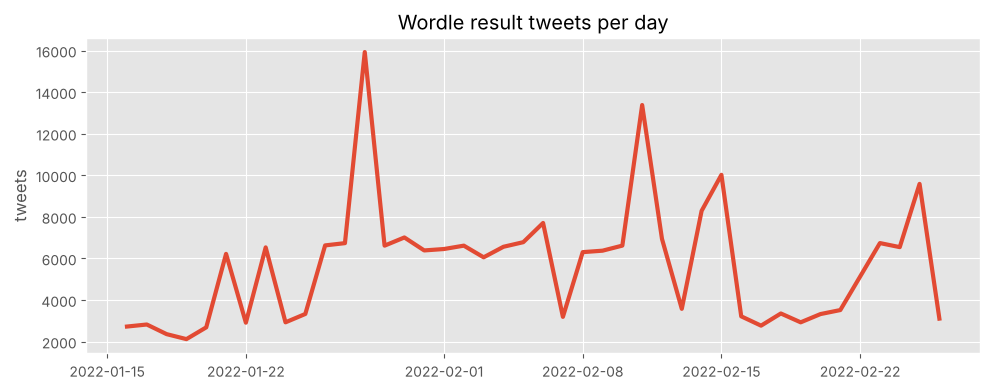

In [8]:
per_day = clean.groupby("tweet_day").size()
ax = per_day.plot(figsize=(10, 4), lw=3, title="Wordle result tweets per day")
ax.set_xlabel("")
ax.set_ylabel("tweets")
plt.tight_layout()
plt.savefig(FIG_DIR / "tweets_per_day.png", dpi=150)
plt.show()

## 5. How many guesses does it take?

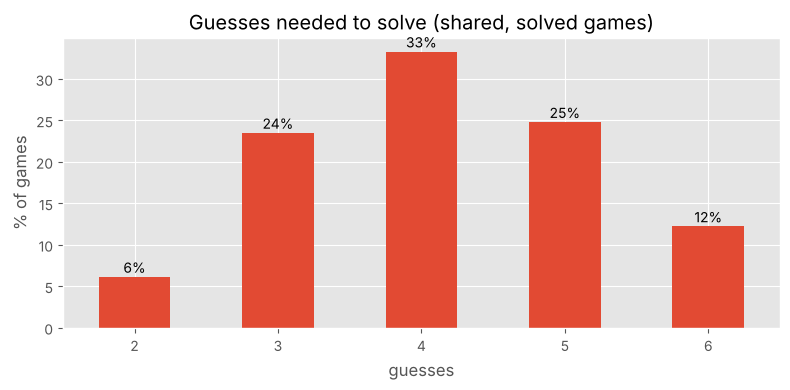

mean guesses: 4.13
solved in 4 or 5: 58.1%
solved in 3 or fewer: 29.7%


In [9]:
dist = clean["attempts"].value_counts(normalize=True).sort_index()
ax = (dist * 100).plot(kind="bar", figsize=(8, 4), rot=0,
                       title="Guesses needed to solve (shared, solved games)")
ax.set_xlabel("guesses")
ax.set_ylabel("% of games")
for i, v in enumerate(dist * 100):
    ax.text(i, v + 0.5, f"{v:.0f}%", ha="center")
plt.tight_layout()
plt.savefig(FIG_DIR / "attempt_distribution.png", dpi=150)
plt.show()

print(f"mean guesses: {clean['attempts'].mean():.2f}")
print(f"solved in 4 or 5: {clean['attempts'].isin([4, 5]).mean():.1%}")
print(f"solved in 3 or fewer: {(clean['attempts'] <= 3).mean():.1%}")

## 6. Which puzzles were hardest?

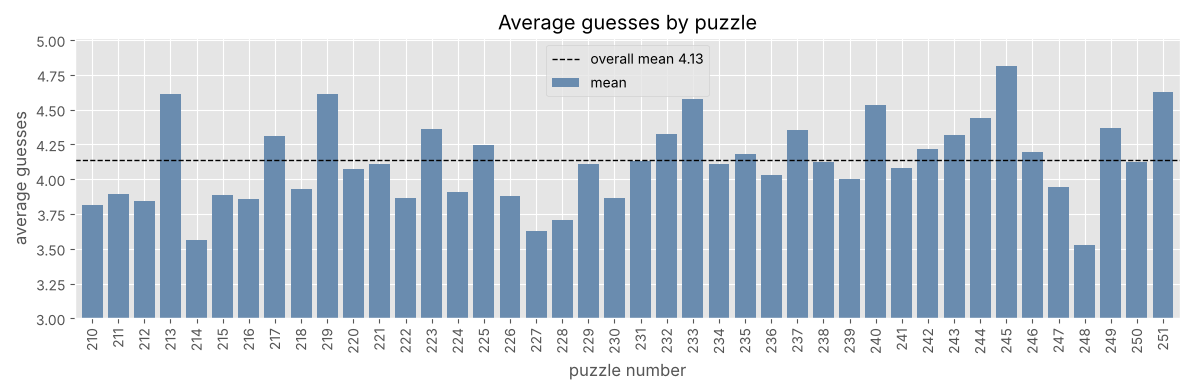

Hardest:
         mean  size
puzzle            
245     4.82  2928
251     4.63  9080
213     4.61  2114

Easiest:
         mean  size
puzzle            
248     3.53  3592
214     3.57  2695
227     3.63  6812


In [10]:
by_puzzle = clean.groupby("puzzle")["attempts"].agg(["mean", "size"])
overall = clean["attempts"].mean()

ax = by_puzzle["mean"].plot(kind="bar", figsize=(12, 4), width=0.8,
                            title="Average guesses by puzzle", color="#6a8caf")
ax.axhline(overall, color="black", ls="--", lw=1, label=f"overall mean {overall:.2f}")
ax.set_ylim(3, by_puzzle["mean"].max() + 0.2)
ax.set_xlabel("puzzle number")
ax.set_ylabel("average guesses")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "difficulty_by_puzzle.png", dpi=150)
plt.show()

print("Hardest:\n", by_puzzle.sort_values("mean", ascending=False).head(3).round(2))
print("\nEasiest:\n", by_puzzle.sort_values("mean").head(3).round(2))

## 7. How does each guess improve?

Average squares of each colour on guess 1, guess 2, and so on, counting only players who actually made that guess.

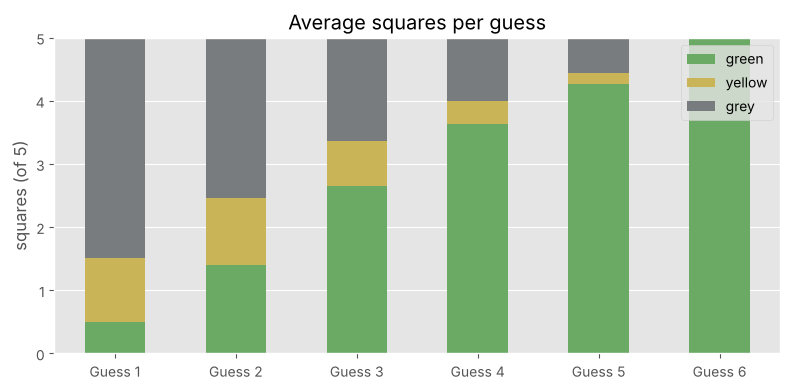

,green,yellow,grey
Guess 1,0.50,1.02,3.49
Guess 2,1.41,1.05,2.54
Guess 3,2.66,0.71,1.63
Guess 4,3.63,0.37,1.00
Guess 5,4.26,0.17,0.56
Guess 6,5.00,0.00,0.00


In [11]:
avg = pd.DataFrame({
    colour: [clean[f"guess{n}_{colour}"].mean() for n in range(1, 7)]
    for colour in ["green", "yellow", "grey"]
}, index=[f"Guess {n}" for n in range(1, 7)])

ax = avg.plot(kind="bar", stacked=True, figsize=(8, 4), rot=0,
              color=["#6aaa64", "#c9b458", "#787c7e"],
              title="Average squares per guess")
ax.set_ylabel("squares (of 5)")
plt.tight_layout()
plt.savefig(FIG_DIR / "squares_by_guess.png", dpi=150)
plt.show()
avg.round(2)

Greens climb steadily while yellows peak at guess 2 and then fall as wrong-spot letters get moved into place. Guess 6 is always five greens here only because every game in this data was solved, so whoever reached guess 6 solved it on that guess.

## 8. Does a good first guess predict a quick solve?

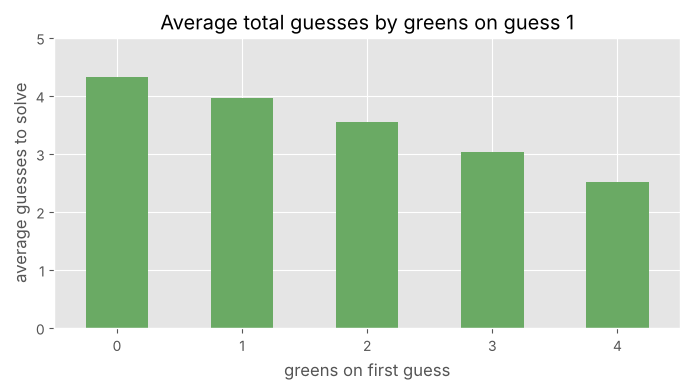

,mean,size
greens on first guess,,
0,4.33,146004
1,3.95,66026
2,3.54,16410
3,3.03,4673
4,2.51,787


In [12]:
first = clean.groupby("guess1_green")["attempts"].agg(["mean", "size"])
first.index.name = "greens on first guess"
ax = first["mean"].plot(kind="bar", figsize=(7, 4), rot=0, color="#6aaa64",
                        title="Average total guesses by greens on guess 1")
ax.set_ylabel("average guesses to solve")
ax.set_ylim(0, 5)
plt.tight_layout()
plt.savefig(FIG_DIR / "first_guess_effect.png", dpi=150)
plt.show()
first.round(2)

## Findings

- Shared games take **4.13 guesses** on average; **58%** are solved in 4 or 5, and about 30% in 3 or fewer.
- Difficulty swings a lot by day: puzzle 245 averaged **4.82** guesses, puzzle 248 only **3.53**.
- Each extra green on the first guess goes with roughly **0.4 fewer** total guesses (4.33 with no greens down to 2.51 with four).
- **Caveat:** there are no failed games in this data. These are results people chose to share, so they overstate how easy Wordle is.

## Data notes

- Grid rows are normalised across dark mode, light mode and high-contrast mode.
- Tweets whose grid doesn't match the claimed score, or doesn't end in a solved row, are excluded, as are repeat posts by the same user for the same puzzle.